# Day 3-01 | Which Boxes Belong to the Same Player? IoU Association

[Open in Colab](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day3/d3_01_tracking_concept_iou_association_en.ipynb)

[English](d3_01_tracking_concept_iou_association_en.ipynb) | [Japanese](d3_01_tracking_concept_iou_association_ja.ipynb) | [Traditional Chinese](d3_01_tracking_concept_iou_association.ipynb)


> Day 2 located players in each frame, but did not determine which box in `Frame 16` corresponds to a box in `Frame 15`.  
> Build an understanding of tracking with a transparent IoU matching procedure, before using ByteTrack for longer video in the next unit.

## Learning Objectives

- Label boxes in consecutive frames as `A0, A1, ...` and `B0, B1, ...`.
- Calculate intersection, union and IoU, then build a matrix of all box pairs.
- Use a heatmap to examine each A box's relationship with every B box.
- Apply a global greedy rule for one-to-one matching and draw the resulting links on the images.

## Key Terms

- **Association**: deciding whether detections in different frames belong to the same target.
- **IoU (Intersection over Union)**: intersection area divided by union area, ranging from 0 to 1.
- **Greedy matching**: repeatedly choosing the highest-scoring remaining pair without conflicts.


## Scope of This Unit

- Compare only two adjacent frames to understand association, rather than implementing all of ByteTrack.
- This exercise can run on a CPU. Reduce `IMGSZ` if YOLO inference is slow.
- Read the images, matrix and matching lines together, rather than inspecting only the final assignment table.


## Workflow

1. Detect players in two adjacent frames and retain player boxes only.
2. Label them `A0...` and `B0...` so matrix rows and columns can be traced to actual boxes.
3. Calculate IoU for every `A_i`/`B_j` pair and draw a heatmap.
4. Sort all candidates by decreasing IoU and create unique one-to-one matches.
5. Draw the matches on both images and discuss failures under rapid motion, occlusion and box jitter.


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "en"

# Locate the repository, prepare the environment and import shared modules.
from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("This Colab runtime cannot mount Drive; using local /content storage.")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)


Course root: /Users/henry753951/Developer/sandbox/basketball-hackathon-course
Assets directory: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
Utility modules: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src


## Step 1 | Select the Video, Model and Adjacent Frames

`FRAME_B = FRAME_A + 1` compares consecutive frames. A shorter time gap generally produces greater overlap for the same player and makes IoU association easier.


In [2]:
# Set the data sources and experiment parameters.
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch, Rectangle
import numpy as np
import pandas as pd

from src.yolo_utils import (
    PLAYER_CLASS_NAMES,
    detector_model_path,
    first_reference_video,
    read_video_frame,
    run_detector_on_image,
)

VIDEO_PATH = first_reference_video(COURSE_ROOT)
MODEL_PATH = detector_model_path(COURSE_ROOT)
FRAME_A = 15
FRAME_B = FRAME_A + 1  # Compare consecutive frames to keep the example simple.
CONF = 0.25            # Discard detections below this confidence.
IMGSZ = 960            # Smaller inputs are faster but may miss small objects.

print("video:", VIDEO_PATH)
print("model:", MODEL_PATH)
print("frames:", FRAME_A, "->", FRAME_B)


video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw/reference_videos/boston-celtics-new-york-knicks-game-1-q1-01.54-01.48.mp4
model: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/yolo26n_basketball_player_best.pt
frames: 15 -> 16


## Step 2 | Label Each Detection Box

`A2` is not a permanent player identity: it means the third box in Frame A. `B2` similarly means the third box in Frame B. Cross-frame identity is established only after association.


In [3]:
# Read both frames, run detection and retain players only.
frame_a = read_video_frame(VIDEO_PATH, FRAME_A)
frame_b = read_video_frame(VIDEO_PATH, FRAME_B)

dets_a, _ = run_detector_on_image(
    MODEL_PATH, frame_a, conf=CONF, imgsz=IMGSZ, frame_index=FRAME_A
)
dets_b, _ = run_detector_on_image(
    MODEL_PATH, frame_b, conf=CONF, imgsz=IMGSZ, frame_index=FRAME_B
)

players_a = [det for det in dets_a if det.class_name in PLAYER_CLASS_NAMES]
players_b = [det for det in dets_b if det.class_name in PLAYER_CLASS_NAMES]

print(f"Frame A: {len(players_a)} player boxes")
print(f"Frame B: {len(players_b)} player boxes")


Frame A: 10 player boxes
Frame B: 9 player boxes


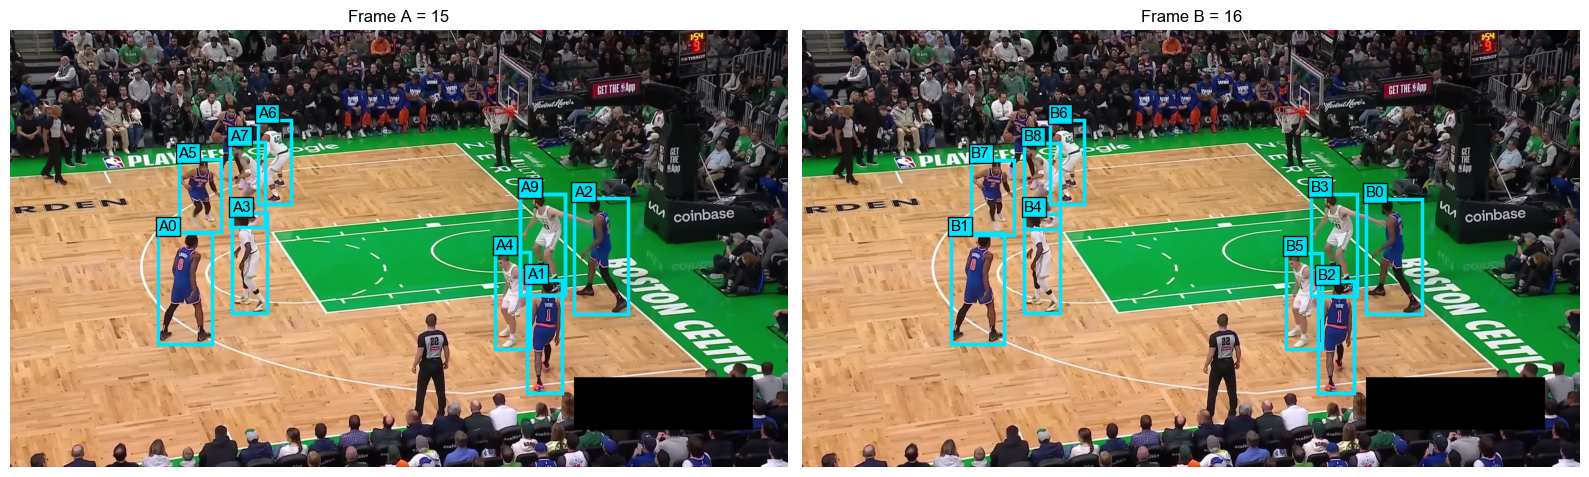

In [4]:
# Draw the A0/B0 matrix labels on the actual boxes.
def draw_indexed_boxes(ax, image, detections, prefix, title):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
    for index, det in enumerate(detections):
        x1, y1, x2, y2 = det.bbox_xyxy
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor="#00E5FF", linewidth=2.5))
        ax.text(x1, max(0, y1 - 6), f"{prefix}{index}", color="black",
                fontsize=11, weight="bold",
                bbox={"facecolor": "#00E5FF", "alpha": 0.9, "pad": 2})

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
draw_indexed_boxes(axes[0], frame_a, players_a, "A", f"Frame A = {FRAME_A}")
draw_indexed_boxes(axes[1], frame_b, players_b, "B", f"Frame B = {FRAME_B}")
plt.tight_layout()
plt.show()


### How to Read the Figure

Row `A1`, column `B3` in the upcoming matrix asks: **how much does box A1 in the left image overlap box B3 in the right image?** Relate the matrix to these images before interpreting its values.


## Step 3 | Calculate IoU as Inspectable Geometric Steps

For boxes $A=(a_{x1},a_{y1},a_{x2},a_{y2})$ and $B=(b_{x1},b_{y1},b_{x2},b_{y2})$, first find their intersection rectangle:

$$
x_{\mathrm{left}}=\max(a_{x1},b_{x1}),\quad
y_{\mathrm{top}}=\max(a_{y1},b_{y1})
$$

$$
x_{\mathrm{right}}=\min(a_{x2},b_{x2}),\quad
y_{\mathrm{bottom}}=\min(a_{y2},b_{y2})
$$

Then calculate:

$$
\mathrm{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}
=\frac{\text{intersection}}{\text{area}_A+\text{area}_B-\text{intersection}}.
$$

- `0`: no overlap.
- Near `1`: the boxes occupy nearly the same location.
- IoU measures spatial overlap only; it does not use jersey color, motion direction or appearance.


In [5]:
# Calculate one pair's IoU step by step, then build the full A/B matrix.
def iou(box_a, box_b):
    '''Return the intersection-over-union of two [x1, y1, x2, y2] boxes.'''
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    # Use larger top-left coordinates and smaller bottom-right coordinates for the intersection.
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    intersection_width = max(0.0, ix2 - ix1)
    intersection_height = max(0.0, iy2 - iy1)
    intersection = intersection_width * intersection_height

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

# matrix[i, j] is the IoU of A_i and B_j; compare every A box with every B box.
matrix = np.zeros((len(players_a), len(players_b)), dtype=float)
for i, det_a in enumerate(players_a):
    for j, det_b in enumerate(players_b):
        matrix[i, j] = iou(det_a.bbox_xyxy, det_b.bbox_xyxy)

matrix_df = pd.DataFrame(
    np.round(matrix, 3),
    index=[f"A{i}" for i in range(len(players_a))],
    columns=[f"B{j}" for j in range(len(players_b))],
)
matrix_df


,B0,B1,B2,B3,B4,B5,B6,B7,B8
A0,0.000,0.986,0.000,0.000,0.000,0.000,0.000,0.006,0.000
A1,0.000,0.000,0.932,0.065,0.000,0.023,0.000,0.000,0.000
A2,0.955,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
A3,0.000,0.000,0.000,0.000,0.978,0.000,0.000,0.000,0.091
A4,0.000,0.000,0.038,0.066,0.000,0.922,0.000,0.000,0.000
A5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.933,0.000
A6,0.000,0.000,0.000,0.000,0.000,0.000,0.991,0.000,0.115
A7,0.000,0.000,0.000,0.000,0.075,0.000,0.082,0.000,0.858
A8,0.000,0.000,0.060,0.928,0.000,0.048,0.000,0.000,0.000
A9,0.000,0.000,0.059,0.933,0.000,0.049,0.000,0.000,0.000


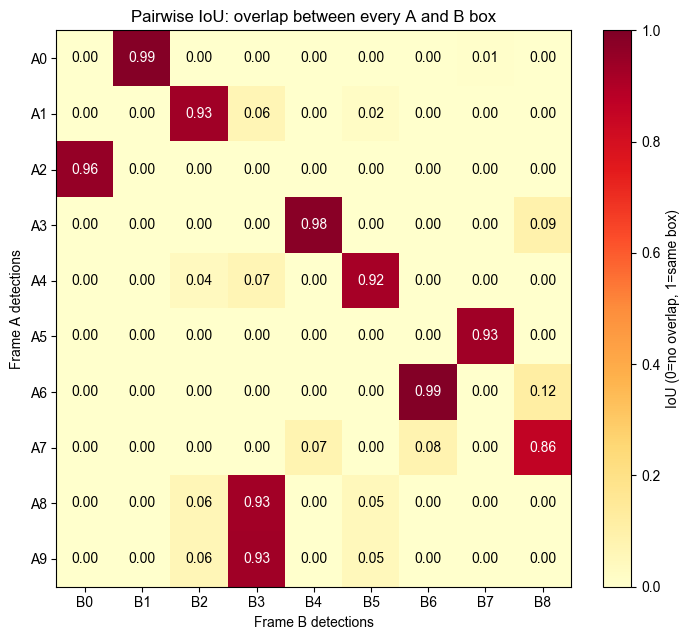

In [6]:
# Show relationships between all boxes using a color scale.
fig, ax = plt.subplots(figsize=(max(6, len(players_b) * 0.8), max(4, len(players_a) * 0.65)))
heatmap = ax.imshow(matrix, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(players_b)), labels=[f"B{j}" for j in range(len(players_b))])
ax.set_yticks(range(len(players_a)), labels=[f"A{i}" for i in range(len(players_a))])
ax.set_xlabel("Frame B detections")
ax.set_ylabel("Frame A detections")
ax.set_title("Pairwise IoU: overlap between every A and B box")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if value > 0.55 else "black")
fig.colorbar(heatmap, ax=ax, label="IoU (0=no overlap, 1=same box)")
plt.tight_layout()
plt.show()


## Step 4 | List the Best Candidate for Each A Box

The largest value in a row indicates the most similar B box. It is not yet a final match: several A boxes may prefer the same B box. The next step enforces one-to-one matching.


In [7]:
# Inspect candidates before enforcing one-to-one matching.
best_match_rows = []
for i in range(matrix.shape[0]):
    if matrix.shape[1] == 0:
        break
    j = int(matrix[i].argmax())
    best_match_rows.append({
        "frame_a_box": f"A{i}",
        "best_frame_b_box": f"B{j}",
        "best_iou": float(matrix[i, j]),
        "passes_threshold": bool(matrix[i, j] >= 0.30),
    })

best_match_df = pd.DataFrame(best_match_rows)
best_match_df


,frame_a_box,best_frame_b_box,best_iou,passes_threshold
0,A0,B1,0.986325,True
1,A1,B2,0.931553,True
2,A2,B0,0.955132,True
3,A3,B4,0.978287,True
4,A4,B5,0.921508,True
5,A5,B7,0.933348,True
6,A6,B6,0.990789,True
7,A7,B8,0.857547,True
8,A8,B3,0.928068,True
9,A9,B3,0.933061,True


## Step 5 | Apply Global Greedy One-to-One Matching

1. List all `(A_i, B_j)` candidates above the threshold.
2. Sort by decreasing IoU.
3. Select the highest remaining score; skip pairs whose A or B box is already used.
4. Continue until no candidates remain.

This is still not ByteTrack. Compared with deciding row by row, it avoids giving `A0` a B box that fits `A1` better simply because `A0` appears first in the loop.


In [8]:
# Select non-conflicting one-to-one pairs by score across all candidates.
IOU_THRESHOLD = 0.30
candidates = [
    (float(matrix[i, j]), i, j)
    for i in range(matrix.shape[0])
    for j in range(matrix.shape[1])
    if matrix[i, j] >= IOU_THRESHOLD
]
candidates.sort(reverse=True)  # Tuples are sorted by their first field, IoU, first.

assignments = []
used_a, used_b = set(), set()
for score, i, j in candidates:
    if i in used_a or j in used_b:
        continue
    used_a.add(i)
    used_b.add(j)
    assignments.append({
        "frame_a_box": f"A{i}",
        "frame_b_box": f"B{j}",
        "iou": round(score, 3),
        "a_index": i,
        "b_index": j,
    })

assignment_df = pd.DataFrame(assignments)
assignment_df[["frame_a_box", "frame_b_box", "iou"]] if not assignment_df.empty else assignment_df


,frame_a_box,frame_b_box,iou
0,A6,B6,0.991
1,A0,B1,0.986
2,A3,B4,0.978
3,A2,B0,0.955
4,A5,B7,0.933
5,A9,B3,0.933
6,A1,B2,0.932
7,A4,B5,0.922
8,A7,B8,0.858


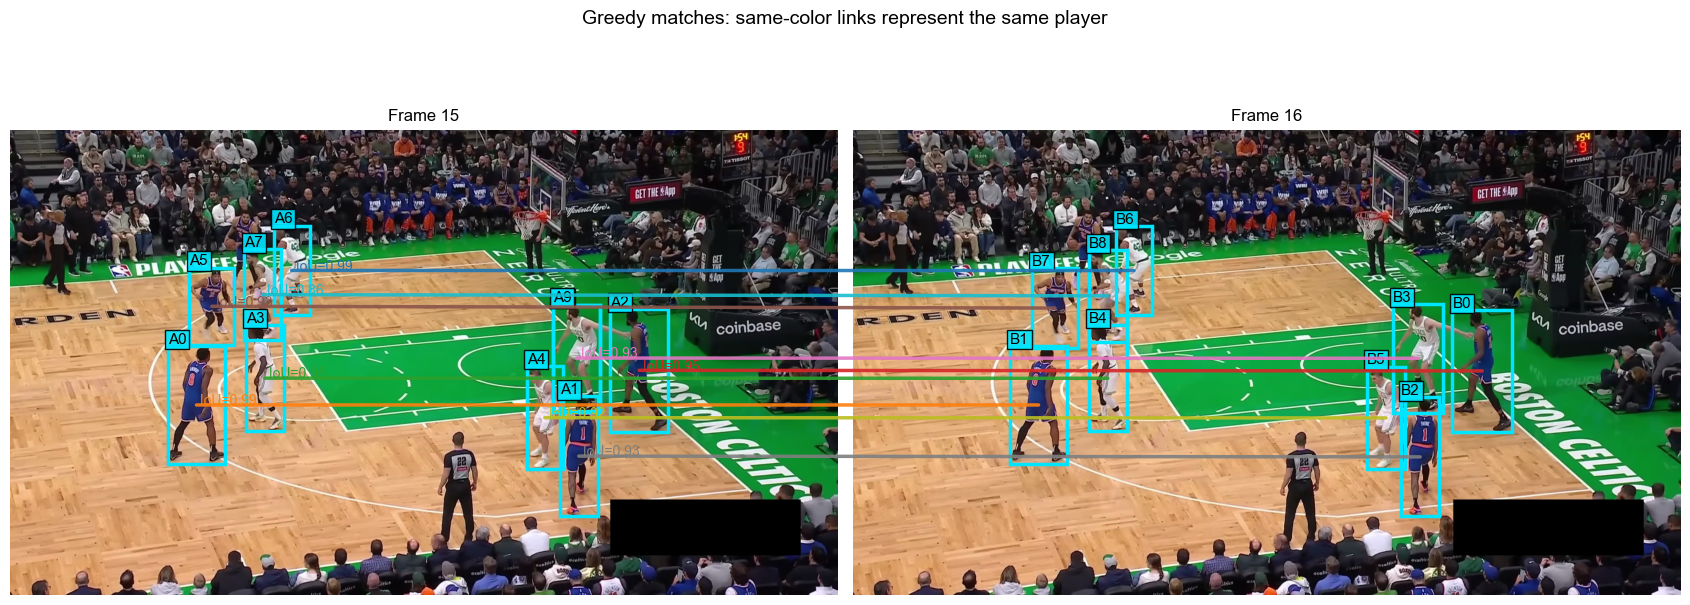

In [9]:
# Draw the assignment table's matches on both images.
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
draw_indexed_boxes(axes[0], frame_a, players_a, "A", f"Frame {FRAME_A}")
draw_indexed_boxes(axes[1], frame_b, players_b, "B", f"Frame {FRAME_B}")

# Use the public colormap API so static checkers can resolve the attribute.
colors = plt.get_cmap("tab10")(np.linspace(0, 1, max(1, len(assignments))))
for color, pair in zip(colors, assignments):
    box_a = players_a[pair["a_index"]].bbox_xyxy
    box_b = players_b[pair["b_index"]].bbox_xyxy
    center_a = ((box_a[0] + box_a[2]) / 2, (box_a[1] + box_a[3]) / 2)
    center_b = ((box_b[0] + box_b[2]) / 2, (box_b[1] + box_b[3]) / 2)
    connection = ConnectionPatch(
        xyA=center_b, coordsA=axes[1].transData,
        xyB=center_a, coordsB=axes[0].transData,
        color=color, linewidth=2.5, alpha=0.9,
    )
    fig.add_artist(connection)
    axes[0].text(*center_a, f" IoU={pair['iou']:.2f}", color=color, weight="bold")

fig.suptitle("Greedy matches: same-color links represent the same player", fontsize=14)
plt.tight_layout()
plt.show()


## From Simple IoU Matching to ByteTrack

IoU alone struggles with fast motion, crossings, occlusion and missed detections. ByteTrack maintains track states and associates high- and low-confidence detections in two stages to reconnect temporarily uncertain targets with existing IDs. The next unit examines `track_id` and trajectories.

### Questions

1. Does any heatmap row have two similarly high scores? What uncertainty does that represent?
2. How does the number of matches change when `IOU_THRESHOLD` is `0.10` or `0.60`?
3. In what basketball situations could the correct pair have a low IoU?


## Outputs

- Consecutive-frame comparison with A/B box labels.
- IoU heatmap for all detection pairs.
- One-to-one assignment table and cross-image matching lines.

This unit intentionally produces no video. First understand the relationship between two frames, then move on to longer tracking.
